In [1]:
 pip install --upgrade pip

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.


In [2]:
pip install pyvisa pyvisa-py numpy matplotlib

Defaulting to user installation because normal site-packages is not writeableNote: you may need to restart the kernel to use updated packages.



In [ ]:
##CHeck whether noise varies with changing low pass filters at same 20MSa/s

In [ ]:
#as we reduce the freq of low pass filter, we see the reduction in noise captured(5mv at 20MHz LP - 3mV at 200KHz)

In [8]:
#pickup coil at 200KHz low pass filter

Connecting to: USB0::0x0957::0x1307::MY48000262::0::INSTR

ARMED on EXT TRIG: Ready for 1,000,000 pts/channel.
Window: 50.0 ms total.

Acquisition complete! Transferring large dataset over USB...
Ch 1 retrieved in 1.18 s
Ch 2 retrieved in 1.19 s
Ch 3 retrieved in 1.15 s
Ch 4 retrieved in 1.18 s
VISA session cleanly closed and memory freed.
Compressing and saving to disk...
Saved 1,000,000 pts x 4 channels to pulse_shot_long_20261027_165434.npz


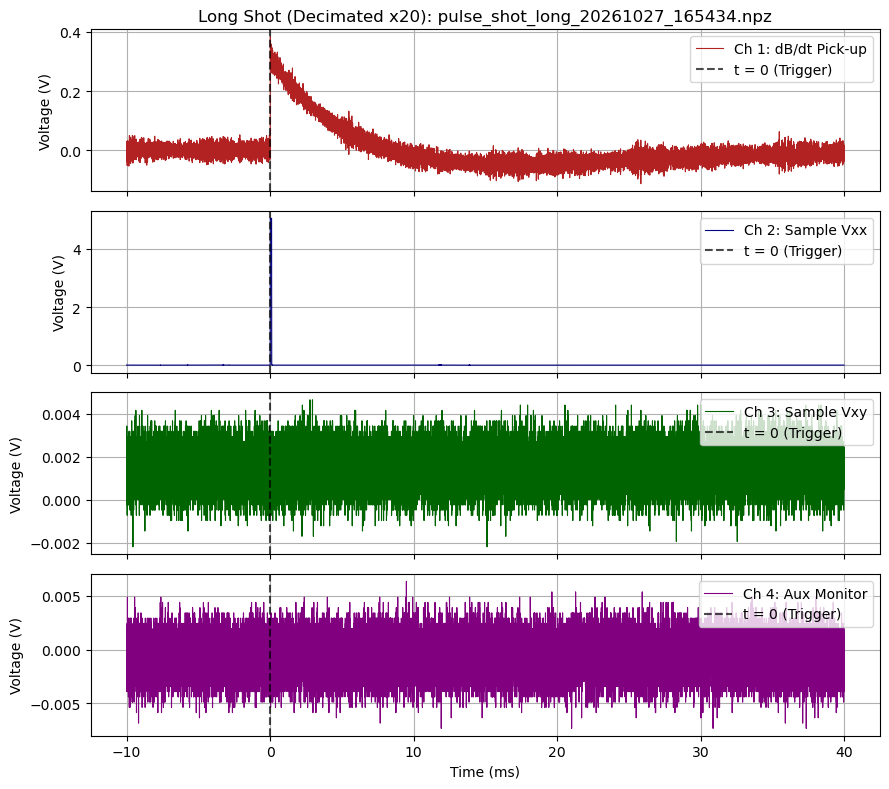

In [10]:
import time
import matplotlib.pyplot as plt
import numpy as np
import pyvisa

VISA_ADDRESS = "USB0::0x0957::0x1307::MY48000262::0::INSTR"

SAMPLE_RATE = 20_000_000 # 20 MSa/s

# Standard memory: 8_000_000 pts (400 ms)
# Option 002:      32_000_000 pts (1.6 seconds)
TOTAL_POINTS = 1_000_000
PRE_TRIG_PTS = 2_00_000 # 80 ms baseline before t=0

CHANNELS = {
    1: {"name": "dB/dt Pick-up", "range": 5.0, "color": "firebrick"},
    2: {"name": "Sample Vxx", "range": 5.0, "color": "navy"},
    3: {"name": "Sample Vxy", "range": 5.0, "color": "darkgreen"},
    4: {"name": "Aux Monitor", "range": 10.0, "color": "purple"},
}

TRIGGER_MODE = "EXT"  # External TTL trigger on rear BNC
TIMEOUT_MS = 180_000  # 3 minutes to allow USB transfer of large arrays


def run_long_acquisition():
    rm = pyvisa.ResourceManager()
    dig = None
    waveforms = {}

    try:
        print(f"Connecting to: {VISA_ADDRESS}")
        dig = rm.open_resource(VISA_ADDRESS)

        # Flush any deadlocked USB FIFO state from previous timeouts
        dig.clear()
        dig.timeout = TIMEOUT_MS

        # Enlarge PyVISA transfer buffer to 4 MB chunks
        dig.chunk_size = 4 * 1024 * 1024

        dig.write("*RST")
        dig.write("*CLS")

        dig.write(f":CONF:ACQ:SRAT {SAMPLE_RATE}")
        dig.write(f":CONF:ACQ:SCO {TOTAL_POINTS}")
        dig.write(f":CONF:ACQ:SPR {PRE_TRIG_PTS}")

        for ch, cfg in CHANNELS.items():
            dig.write(f":CONF:CHAN:ATTR (@{ch}), {cfg['range']}, DC, LP_200_KHZ")

        dig.write(":FORM:DATA:REAL REAL,64")
        dig.write(":FORM:BORD NORM")

        dig.write(":CONF:ARM:SOUR IMM")
        if TRIGGER_MODE == "EXT":
            dig.write(":CONF:TRIG:SOUR EXT")
            dig.write(":CONF:EXT:INP POS")
            print("\n" + "=" * 60)
            print(f"ARMED on EXT TRIG: Ready for {TOTAL_POINTS:,} pts/channel.")
            print(f"Window: {(TOTAL_POINTS/SAMPLE_RATE)*1e3:.1f} ms total.")
            print("=" * 60 + "\n")
        else:
            dig.write(":CONF:TRIG:SOUR IMM")
            print("Running bench test...")

        # Drain and print any SCPI setup warnings/errors before arming
        err = dig.query(":SYST:ERR?").strip()
        if not (err.startswith("+0") or err.startswith("0")):
            print(f"WARNING - Hardware SCPI Setup Error: {err}")

        dig.write(":INIT")
        dig.query("*OPC?")
        print("Acquisition complete! Transferring large dataset over USB...")

        for ch in CHANNELS:
            t0 = time.time()
            waveforms[f"v_ch{ch}"] = dig.query_binary_values(
                f":FETC:WAV:VOLT? (@{ch})",
                datatype="d",
                is_big_endian=True,
                container=np.array,
            )
            print(f"Ch {ch} retrieved in {time.time() - t0:.2f} s")

    finally:
        # Always release VISA session handles & memory even on error/timeout
        if dig is not None:
            try:
                dig.close()
            except Exception:
                pass
        try:
            rm.close()
        except Exception:
            pass
        print("VISA session cleanly closed and memory freed.")

    if len(waveforms) == len(CHANNELS):
        time_ms = ((np.arange(TOTAL_POINTS) - PRE_TRIG_PTS) / SAMPLE_RATE) * 1e3
        timestamp = time.strftime("%Y%m%d_%H%M%S")
        shot_filename = f"pulse_shot_long_{timestamp}.npz"

        print("Compressing and saving to disk...")
        np.savez_compressed(
            shot_filename,
            time_ms=time_ms,
            sample_rate=SAMPLE_RATE,
            pre_trig_pts=PRE_TRIG_PTS,
            **waveforms,
        )
        print(f"Saved {TOTAL_POINTS:,} pts x 4 channels to {shot_filename}")

        # Decimate data for rapid plotting
        decimate_factor = max(1, TOTAL_POINTS // 50_000)
        fig, axes = plt.subplots(4, 1, figsize=(9, 8), sharex=True)
        for idx, (ch, cfg) in enumerate(CHANNELS.items()):
            ax = axes[idx]
            ax.plot(
                time_ms[::decimate_factor],
                waveforms[f"v_ch{ch}"][::decimate_factor],
                color=cfg["color"],
                lw=0.8,
                label=f"Ch {ch}: {cfg['name']}",
            )
            ax.axvline(0, color="black", linestyle="--", alpha=0.7, label="t = 0 (Trigger)")
            ax.set_ylabel("Voltage (V)")
            ax.grid(True)
            ax.legend(loc="upper right")

        axes[-1].set_xlabel("Time (ms)")
        axes[0].set_title(f"Long Shot (Decimated x{decimate_factor}): {shot_filename}")
        plt.tight_layout()
        plt.show()


if __name__ == "__main__":
    run_long_acquisition()

In [ ]:
##feedback for above: reduce to 10mV noise at 20MHz LP_filter. Issue lies in hardware. code is good,proceed for frontend.